# BERT vs. TF-IDF + Logistic Regression: Results

This notebook shows the results of `bert.ipynb` without retraining anything. It only reads the files that `bert.ipynb` saved in `results/`, so it runs in a few seconds and needs no GPU.

**Where the numbers come from:** one full run of `bert.ipynb` (`bert-base-uncased`, 3 epochs, learning rate 2e-5, batch size 16, seed 42, run on an Apple M1 GPU). Each model was trained once, so small differences between rows can be due to chance.

Each model was trained on two training sets and evaluated on the same evaluation sets:

| Training data | Size |
|---|---|
| HealthVer only | 10,590 |
| HealthVer + HealthFC | 11,186 |

In [1]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

REPO_URL = "https://github.com/dong135790/NLP-Final-Project.git"

# Find the results folder: run from notebooks/, from the repo root, or (on Colab) clone the repo.
if Path("../results/bert_vs_lr_results.csv").exists():
    RESULTS_DIR = Path("../results")
elif Path("results/bert_vs_lr_results.csv").exists():
    RESULTS_DIR = Path("results")
else:
    if not Path("NLP-Final-Project").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    RESULTS_DIR = Path("NLP-Final-Project/results")

results = pd.read_csv(RESULTS_DIR / "bert_vs_lr_results.csv")
predictions = pd.read_csv(RESULTS_DIR / "bert_vs_lr_predictions.csv")
history = pd.read_csv(RESULTS_DIR / "bert_training_history.csv")

LABELS = ["Supports", "Refutes", "Neutral"]
EVAL_ORDER = ["HealthVer dev", "HealthVer test", "HealthFC dev", "HealthFC test"]

print("Result rows:", len(results), "| prediction rows:", len(predictions))

Result rows: 16 | prediction rows: 7596


## 1. Overall comparison

Macro-F1 is the main metric because it weights the three classes equally.

HealthFC dev and test have fewer than 80 examples each, so one example is worth about 1.3 accuracy points there. Base the main conclusions on HealthVer test.

In [2]:
def comparison_table(metric):
    table = results.pivot_table(index=["model", "train_data"], columns="eval_set", values=metric)
    return table[EVAL_ORDER].round(3)


print("Macro-F1")
display(comparison_table("macro_f1"))
print("Accuracy")
display(comparison_table("accuracy"))

Macro-F1


eval_set                          HealthVer dev  HealthVer test  HealthFC dev  \
model       train_data                                                          
BERT        HealthVer + HealthFC          0.722           0.726         0.713   
            HealthVer only                0.713           0.717         0.402   
TF-IDF + LR HealthVer + HealthFC          0.622           0.618         0.623   
            HealthVer only                0.628           0.618         0.480   

eval_set                          HealthFC test  
model       train_data                           
BERT        HealthVer + HealthFC          0.719  
            HealthVer only                0.280  
TF-IDF + LR HealthVer + HealthFC          0.645  
            HealthVer only                0.370

Accuracy


eval_set                          HealthVer dev  HealthVer test  HealthFC dev  \
model       train_data                                                          
BERT        HealthVer + HealthFC          0.772           0.747         0.795   
            HealthVer only                0.759           0.733         0.397   
TF-IDF + LR HealthVer + HealthFC          0.648           0.628         0.705   
            HealthVer only                0.655           0.629         0.577   

eval_set                          HealthFC test  
model       train_data                           
BERT        HealthVer + HealthFC          0.789  
            HealthVer only                0.303  
TF-IDF + LR HealthVer + HealthFC          0.711  
            HealthVer only                0.513

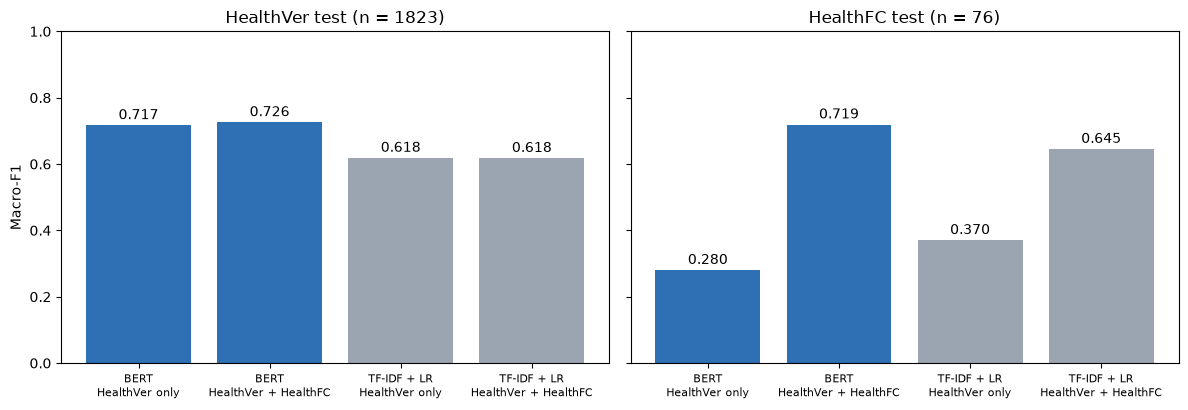

In [3]:
test_results = results[results["eval_set"].str.endswith("test")].copy()
test_results["setup"] = test_results["model"] + "\n" + test_results["train_data"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, eval_name in zip(axes, ["HealthVer test", "HealthFC test"]):
    subset = test_results[test_results["eval_set"] == eval_name]
    colors = ["#9aa5b1" if m == "TF-IDF + LR" else "#2f6fb3" for m in subset["model"]]
    bars = ax.bar(subset["setup"], subset["macro_f1"], color=colors)
    ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_title(f"{eval_name} (n = {subset['n'].iloc[0]})")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Macro-F1")
plt.tight_layout()
plt.show()

## 2. Per-class results on the test sets

In [4]:
per_class = test_results.set_index(["eval_set", "model", "train_data"]).sort_index()

print("F1 per class")
display(per_class[[f"f1_{label}" for label in LABELS]].round(3))
print("Precision per class")
display(per_class[[f"precision_{label}" for label in LABELS]].round(3))
print("Recall per class")
display(per_class[[f"recall_{label}" for label in LABELS]].round(3))

F1 per class


f1_Supports  f1_Refutes  \
eval_set       model       train_data                                      
HealthFC test  BERT        HealthVer + HealthFC        0.762       0.522   
                           HealthVer only              0.632       0.167   
               TF-IDF + LR HealthVer + HealthFC        0.636       0.480   
                           HealthVer only              0.444       0.000   
HealthVer test BERT        HealthVer + HealthFC        0.747       0.609   
                           HealthVer only              0.714       0.602   
               TF-IDF + LR HealthVer + HealthFC        0.577       0.540   
                           HealthVer only              0.565       0.552   

                                                 f1_Neutral  
eval_set       model       train_data                        
HealthFC test  BERT        HealthVer + HealthFC       0.874  
                           HealthVer only             0.043  
               TF-IDF + LR HealthVer + HealthFC       0.819  
                           HealthVer only             0.667  
HealthVer test BERT        HealthVer + HealthFC       0.821  
                           HealthVer only             0.835  
               TF-IDF + LR HealthVer + HealthFC       0.736  
                           HealthVer only             0.738

Precision per class


precision_Supports  \
eval_set       model       train_data                                 
HealthFC test  BERT        HealthVer + HealthFC               0.842   
                           HealthVer only                     0.529   
               TF-IDF + LR HealthVer + HealthFC               0.667   
                           HealthVer only                     0.387   
HealthVer test BERT        HealthVer + HealthFC               0.714   
                           HealthVer only                     0.703   
               TF-IDF + LR HealthVer + HealthFC               0.610   
                           HealthVer only                     0.604   

                                                 precision_Refutes  \
eval_set       model       train_data                                
HealthFC test  BERT        HealthVer + HealthFC              0.500   
                           HealthVer only                    0.108   
               TF-IDF + LR HealthVer + HealthFC              0.429   
                           HealthVer only                    0.000   
HealthVer test BERT        HealthVer + HealthFC              0.658   
                           HealthVer only                    0.581   
               TF-IDF + LR HealthVer + HealthFC              0.474   
                           HealthVer only                    0.490   

                                                 precision_Neutral  
eval_set       model       train_data                               
HealthFC test  BERT        HealthVer + HealthFC              0.844  
                           HealthVer only                    0.200  
               TF-IDF + LR HealthVer + HealthFC              0.829  
                           HealthVer only                    0.692  
HealthVer test BERT        HealthVer + HealthFC              0.825  
                           HealthVer only                    0.868  
               TF-IDF + LR HealthVer + HealthFC              0.775  
                           HealthVer only                    0.761

Recall per class


recall_Supports  \
eval_set       model       train_data                              
HealthFC test  BERT        HealthVer + HealthFC            0.696   
                           HealthVer only                  0.783   
               TF-IDF + LR HealthVer + HealthFC            0.609   
                           HealthVer only                  0.522   
HealthVer test BERT        HealthVer + HealthFC            0.784   
                           HealthVer only                  0.726   
               TF-IDF + LR HealthVer + HealthFC            0.547   
                           HealthVer only                  0.531   

                                                 recall_Refutes  \
eval_set       model       train_data                             
HealthFC test  BERT        HealthVer + HealthFC           0.545   
                           HealthVer only                 0.364   
               TF-IDF + LR HealthVer + HealthFC           0.545   
                           HealthVer only                 0.000   
HealthVer test BERT        HealthVer + HealthFC           0.567   
                           HealthVer only                 0.624   
               TF-IDF + LR HealthVer + HealthFC           0.628   
                           HealthVer only                 0.633   

                                                 recall_Neutral  
eval_set       model       train_data                            
HealthFC test  BERT        HealthVer + HealthFC           0.905  
                           HealthVer only                 0.024  
               TF-IDF + LR HealthVer + HealthFC           0.810  
                           HealthVer only                 0.643  
HealthVer test BERT        HealthVer + HealthFC           0.817  
                           HealthVer only                 0.805  
               TF-IDF + LR HealthVer + HealthFC           0.702  
                           HealthVer only                 0.717

## 3. Confusion matrices

First row: both models trained on the combined data, evaluated on HealthVer test.

Second row: BERT on HealthFC test, trained without and with HealthFC. This shows what happens when a model trained only on COVID-19 claims is applied to general health claims.

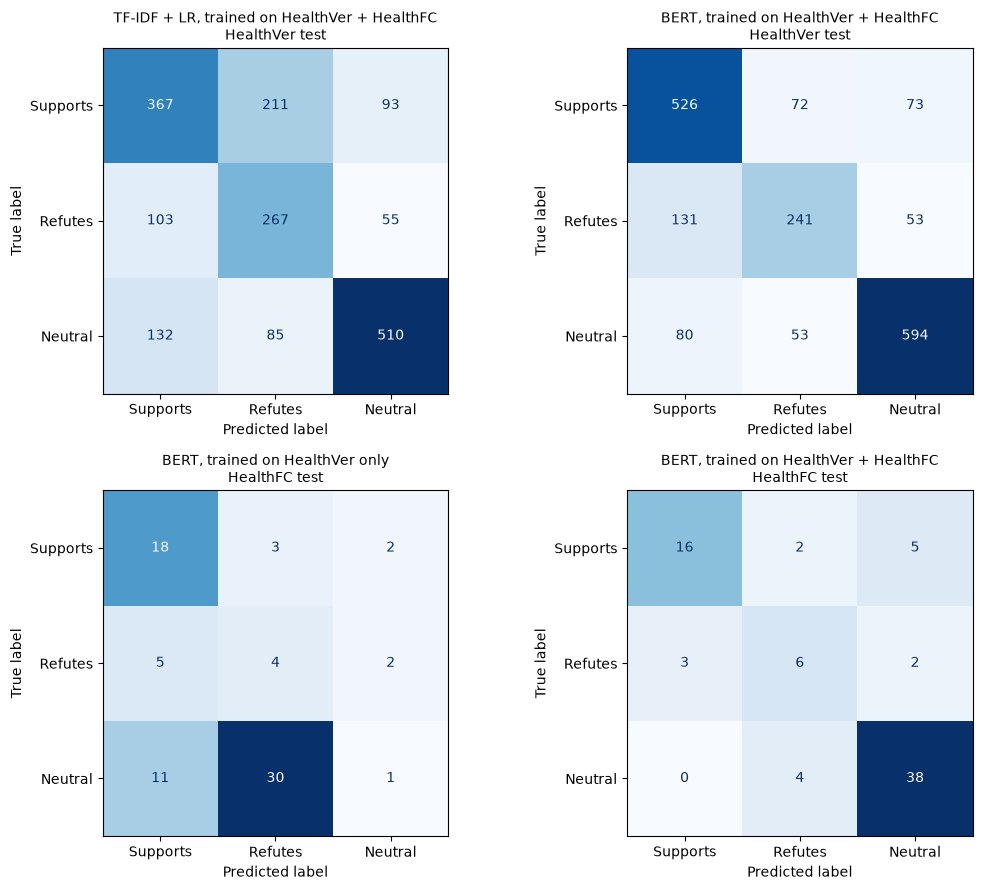

In [5]:
def get_predictions(model, train_data, eval_set):
    rows = predictions[
        (predictions["model"] == model)
        & (predictions["train_data"] == train_data)
        & (predictions["eval_set"] == eval_set)
    ]
    assert len(rows) > 0, (model, train_data, eval_set)
    return rows.reset_index(drop=True)


plots = [
    ("TF-IDF + LR", "HealthVer + HealthFC", "HealthVer test"),
    ("BERT", "HealthVer + HealthFC", "HealthVer test"),
    ("BERT", "HealthVer only", "HealthFC test"),
    ("BERT", "HealthVer + HealthFC", "HealthFC test"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (model, train_data, eval_set) in zip(axes.ravel(), plots):
    rows = get_predictions(model, train_data, eval_set)
    ConfusionMatrixDisplay.from_predictions(
        rows["label"], rows["prediction"], labels=LABELS, cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(f"{model}, trained on {train_data}\n{eval_set}", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Error analysis on HealthVer test

Both models below were trained on the combined data. Predicting **Supports** for a claim the evidence actually **Refutes** is the most harmful mistake for a fact-checking tool, so it is counted separately.

In [6]:
lr_rows = get_predictions("TF-IDF + LR", "HealthVer + HealthFC", "HealthVer test")
bert_rows = get_predictions("BERT", "HealthVer + HealthFC", "HealthVer test")
assert (lr_rows["claim"] == bert_rows["claim"]).all() and (lr_rows["evidence"] == bert_rows["evidence"]).all()

analysis = lr_rows[["claim", "evidence", "label"]].copy()
analysis["lr_pred"] = lr_rows["prediction"]
analysis["bert_pred"] = bert_rows["prediction"]

lr_correct = analysis["lr_pred"] == analysis["label"]
bert_correct = analysis["bert_pred"] == analysis["label"]

print("Agreement between the two models")
display(pd.crosstab(
    lr_correct.map({True: "LR correct", False: "LR wrong"}),
    bert_correct.map({True: "BERT correct", False: "BERT wrong"}),
    rownames=[None], colnames=[None],
))

confusions = []
for true_label, predicted in [("Refutes", "Supports"), ("Supports", "Refutes")]:
    is_true = analysis["label"] == true_label
    confusions.append({
        "true label": true_label,
        "predicted as": predicted,
        "TF-IDF + LR": int((is_true & (analysis["lr_pred"] == predicted)).sum()),
        "BERT": int((is_true & (analysis["bert_pred"] == predicted)).sum()),
        "examples with this true label": int(is_true.sum()),
    })
pd.DataFrame(confusions)

Agreement between the two models


,BERT correct,BERT wrong
LR correct,999,145
LR wrong,362,317


,true label,predicted as,TF-IDF + LR,BERT,examples with this true label
0,Refutes,Supports,103,131,425
1,Supports,Refutes,211,72,671


In [7]:
pd.set_option("display.max_colwidth", None)

print("True Refutes that BERT predicted as Supports (first 5)")
display(analysis[(analysis["label"] == "Refutes") & (analysis["bert_pred"] == "Supports")].head(5))

print("Examples the baseline got wrong and BERT got right (first 5)")
display(analysis[~lr_correct & bert_correct].head(5))

True Refutes that BERT predicted as Supports (first 5)


,claim,evidence,label,lr_pred,bert_pred
22,"Hot weather can spread the virus more as it may get you more out there, make you more mobile and you would actually interact with more people",The current study focuses on the relationship between environmental parameters and the growth rate of COVID-19. The statistical analysis suggests that the temperature changes retarded the growth rate and found that -6.28C and +14.51C temperature is the favorable range for COVID-19 growth.,Refutes,Supports,Supports
51,clinical trials are needed to determine if endogenously created vitamin D could be effective for the prevention and treatment of COVID-19,"Several studies demonstrated the role of vitamin D in reducing the risk of acute viral respiratory tract infections and pneumonia. These include direct inhibition with viral replication or with anti-inflammatory or immunomodulatory ways. In the meta-analysis, vitamin D supplementation has been shown as safe and effective against acute respiratory tract infections. Thus, people who are at higher risk of vitamin D deficiency during this global pandemic should consider taking vitamin D supplements to maintain the circulating 25(OH)D in the optimal levels (75-125nmol/L).",Refutes,Supports,Supports
73,"If you're worried about corona, only the N95 mask will protect you","Surgical face masks significantly reduced detection of influenza virus RNA in respiratory droplets and coronavirus RNA in aerosols, with a trend toward reduced detection of coronavirus RNA in respiratory droplets.",Refutes,Refutes,Supports
80,clinical trials are needed to determine if endogenously created vitamin D could be effective for the prevention and treatment of COVID-19,"testing positive for COVID-19 was associated with increasing age(RR(age<50)=1.05,p<0.021;RR(age[]50)=1.02,p<0.064)), non-white race(RR=2.54,p<0.01) and being likely vitamin D deficient (deficient/treatment-not-increased:RR=1.77,p<0.02) as compared to likely vitamin D sufficient(not-deficient/treatment-not-decreased), with predicted COVID-19 rates in the vitamin D deficient group of 21.6%(95%CI[14.0%-29.2%] ) versus 12.2%(95%CI[8.9%-15.4%]) in the vitamin D sufficient group.",Refutes,Supports,Supports
89,it appears that the virus that causes COVID-19 can spread from people to animals after close contact with people with COVID-19,It is known that transmission from person to person is the most important way to spread.,Refutes,Neutral,Supports


Examples the baseline got wrong and BERT got right (first 5)


,claim,evidence,label,lr_pred,bert_pred
1,N95 masks are better than clothe masks,"However, wearing N95 respirators can prevent 73 more (95% CI 46-91) clinical respiratory infections per 1000 HCWs compared to surgical masks (2 RCTs; 2594 patients; low quality of evidence).",Supports,Refutes,Supports
17,"No experts are remotely advocating for people to take up smoking to prevent COVID-19, but some researchers have theorized nicotine may be playing some role in keeping the virus at bay","Cannabis smoking is linked with poor respiratory health, immunosuppression and multiple contaminants. Potential synergism between the two epidemics would represent a major public health convergence. Cigarettes were implicated with disease severity in Wuhan, China.",Refutes,Supports,Refutes
18,it appears that the virus that causes COVID-19 can spread from people to animals after close contact with people with COVID-19,A novel coronavirus emerged in human populations and spread rapidly to cause the global coronavirus disease 2019 pandemic.,Neutral,Supports,Neutral
19,there is no scientific evidence establishing a link between ibuprofen and worsening of covid-19,The Expert Working Group on the Commission of Human Medicines in the UK and other organizations have stated that there is insufficient evidence to establish a link between ibuprofen and susceptibility to or exacerbation of COVID-19.,Supports,Refutes,Supports
20,the Covid-19 coronavirus can stay on various surfaces for a while,"Our findings of extensive viral RNA contamination of surfaces and air across a range of acute healthcare settings in the absence of cultured virus underlines the potential risk from surface and air contamination in managing COVID-19, and the need for effective use of PPE, social distancing, and hand/surface hygiene.",Supports,Refutes,Supports


## 5. BERT training history

Macro-F1 on the dev data after each epoch. The epoch with the best dev score was kept for evaluation.

In [8]:
history.round(4)

,run,epoch,train_loss,dev_macro_f1
0,HealthVer only,1,0.8254,0.6921
1,HealthVer only,2,0.4461,0.7121
2,HealthVer only,3,0.2545,0.7133
3,HealthVer + HealthFC,1,0.8270,0.6020
4,HealthVer + HealthFC,2,0.4613,0.7203
5,HealthVer + HealthFC,3,0.2536,0.7212
